<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>ALWANSYAH</span><span>(H061241090)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>


---

### 1. PROMPT ANALISIS STUDI KASUS GEOFISIKA DENGAN METODE SEISMIK REFLEKSI

ROLE (R):

Bertindak sebagai geofisikawan yang memahami survei seismik refleksi, terutama dalam membaca waktu tempuh gelombang, pola reflektor, kontinuitas lapisan, dan kondisi struktur bawah permukaan. Gunakan pendekatan yang sesuai dengan prinsip interpretasi data seismik.

TASK (T):

Analisis studi kasus yang diberikan dengan menggunakan metode seismik refleksi. Identifikasi pola refleksi yang terlihat, tentukan kemungkinan susunan lapisan bawah permukaan, analisis perubahan kedalaman atau kemenerusan reflektor, kemudian berikan interpretasi kondisi geologi berdasarkan informasi yang tersedia.

CONTEXT (C):

Data berasal dari survei seismik refleksi yang bertujuan memperoleh gambaran struktur bawah permukaan. Interpretasi dilakukan berdasarkan informasi waktu tempuh, posisi reflektor, karakter amplitudo, kontinuitas refleksi, serta informasi pendukung apabila tersedia. Hasil analisis ditujukan untuk kebutuhan studi geofisika dan harus mudah dipahami oleh mahasiswa.

INPUT (I):

Masukkan data studi kasus berupa:
- Penampang atau data seismik refleksi.
- Informasi waktu tempuh gelombang jika tersedia.
- Parameter akuisisi seismik.
- Informasi geologi daerah penelitian jika tersedia.
- Data pendukung lain yang berhubungan dengan interpretasi.

CONSTRAINTS (K):

Gunakan prinsip dasar metode seismik refleksi dan hanya gunakan informasi yang tersedia pada data. Jangan menentukan jenis batuan secara pasti apabila data belum mendukung. Jika terdapat ketidakpastian, jelaskan sebagai kemungkinan interpretasi. Hindari pembahasan yang tidak berhubungan dengan data seismik.

OUTPUT (O):

Berikan hasil dalam bentuk narasi yang menjelaskan karakter reflektor, susunan dan kemenerusan lapisan bawah permukaan, kemungkinan perubahan struktur geologi, serta kesimpulan mengenai kondisi bawah permukaan berdasarkan hasil interpretasi seismik refleksi.

## Studi Kasus Seismik Refleksi
Simulasi penampang seismik refleksi untuk memperlihatkan reflektor berlapis, perubahan kemenerusan reflektor, dan satu indikasi gangguan struktur. Sumbu vertikal menggunakan waktu tempuh dua arah (*two-way travel time/TWT*), bukan kedalaman langsung.

SEISMIK REFLEKSI - DATA SINTETIS
Panjang lintasan       : 1000 m
Rentang waktu TWT      : 0–800 ms
Jumlah sampel lateral  : 251
Jumlah sampel waktu    : 301
Data merupakan simulasi, bukan data lapangan.


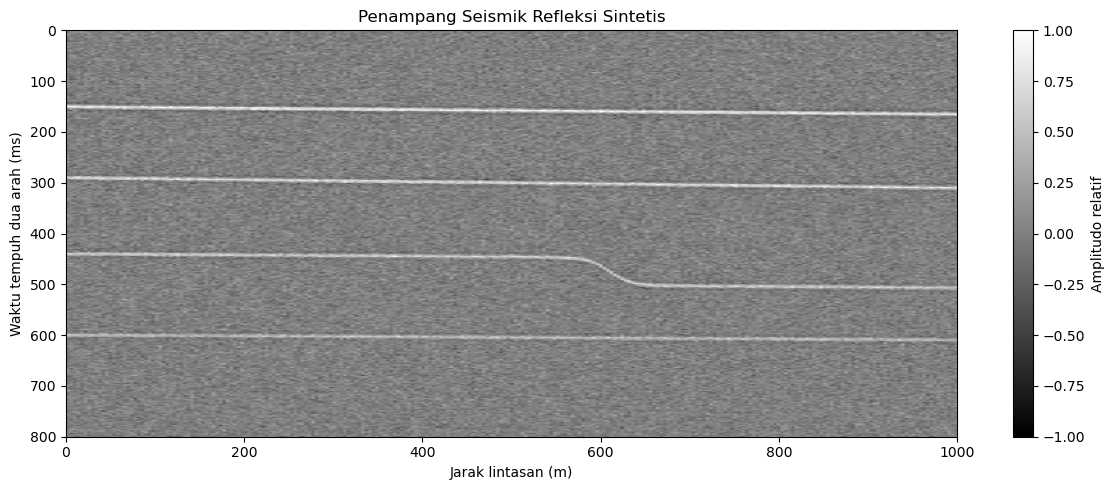

Grafik disimpan sebagai: seismik_refleksi_sintetis.png


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# ============================================================
# 1. MEMBUAT DATA SEISMIK REFLEKSI SINTETIS
# ============================================================
rng = np.random.default_rng(12)
x = np.linspace(0, 1000, 251)          # posisi lintasan (m)
t_ms = np.linspace(0, 800, 301)        # waktu tempuh dua arah (ms)
X, T = np.meshgrid(x, t_ms)

# Reflektor sintetis: waktu kedatangan berubah perlahan terhadap posisi
reflector_times = [
    150 + 0.015*x,
    290 + 0.020*x,
    440 + 0.012*x,
    600 + 0.010*x
]
section = 0.10 * rng.normal(size=X.shape)

# Menambahkan reflektor berupa gelombang beramplitudo terlokalisasi
for i, tr in enumerate(reflector_times):
    # Gangguan struktur sederhana pada reflektor ke-3
    tr_mod = tr.copy()
    if i == 2:
        tr_mod = tr_mod + 55/(1 + np.exp(-(x-610)/12))
    event = np.exp(-((T - tr_mod[None, :]) / 5.5)**2)
    section += (0.85 - 0.12*i) * event * np.cos(2*np.pi*(T-tr_mod[None, :])/18)

# Informasi model
print("="*58)
print("SEISMIK REFLEKSI - DATA SINTETIS")
print("="*58)
print(f"Panjang lintasan       : {x.max():.0f} m")
print(f"Rentang waktu TWT      : {t_ms.min():.0f}–{t_ms.max():.0f} ms")
print(f"Jumlah sampel lateral  : {len(x)}")
print(f"Jumlah sampel waktu    : {len(t_ms)}")
print("Data merupakan simulasi, bukan data lapangan.")

# Visualisasi penampang
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(section, extent=[x.min(), x.max(), t_ms.max(), t_ms.min()],
               aspect="auto", cmap="gray", vmin=-1.0, vmax=1.0)
fig.colorbar(im, ax=ax, label="Amplitudo relatif")
ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("Waktu tempuh dua arah (ms)")
ax.set_title("Penampang Seismik Refleksi Sintetis")
ax.grid(False)
fig.tight_layout()
filename = "seismik_refleksi_sintetis.png"
fig.savefig(filename, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan sebagai: {filename}")



Penampang sintetis memperlihatkan beberapa reflektor yang relatif menerus dan memiliki kemiringan kecil. Reflektor yang lebih dalam menunjukkan perubahan waktu tempuh secara bertahap. Pada reflektor ketiga terdapat pergeseran waktu di sekitar jarak 600 m yang sengaja dibuat sebagai contoh gangguan struktur atau perubahan geometri lapisan. Pada data nyata, interpretasi perlu memeriksa kontinuitas, amplitudo, kemiringan, kemungkinan sesar, serta hasil pemrosesan seismik. Waktu tempuh tidak dapat langsung dianggap sebagai kedalaman tanpa informasi kecepatan.

---

### 2. PROMPT INTERPRETASI BAWAH PERMUKAAN MENGGUNAKAN METODE ERT

ROLE (R):

Berperan sebagai geofisikawan yang memiliki kemampuan dalam pengolahan dan interpretasi survei Electrical Resistivity Tomography. Pahami hubungan antara nilai resistivitas, kondisi material bawah permukaan, kedalaman investigasi, dan kemungkinan perubahan litologi.

TASK (T):

Lakukan interpretasi terhadap data ERT yang diberikan. Analisis persebaran nilai resistivitas pada penampang, bedakan zona resistivitas rendah dan tinggi, kemudian tentukan kemungkinan material atau kondisi geologi yang berhubungan dengan setiap zona tersebut.

CONTEXT (C):

Survei ERT digunakan untuk mengetahui variasi sifat kelistrikan material di bawah permukaan. Data dapat berupa nilai resistivitas semu, hasil inversi 2D, atau penampang resistivitas. Interpretasi harus mempertimbangkan posisi, kedalaman, pola anomali, dan hubungan antarzona resistivitas.

INPUT (I):

Data yang digunakan dapat berupa:
- Penampang hasil inversi ERT.
- Nilai resistivitas semu.
- Konfigurasi elektroda yang digunakan.
- Jarak antar elektroda dan panjang lintasan.
- Kedalaman atau posisi zona anomali.
- Informasi geologi daerah penelitian apabila tersedia.

CONSTRAINTS (K):

Interpretasi harus berdasarkan pola dan rentang nilai resistivitas yang terdapat pada data. Jangan langsung menetapkan suatu zona sebagai jenis batuan tertentu tanpa dasar yang jelas. Bedakan antara hasil pengamatan data dan interpretasi geologi. Apabila data tidak cukup untuk menentukan material secara pasti, gunakan istilah kemungkinan atau indikasi.

OUTPUT (O):

Susun hasil analisis dalam bentuk uraian yang menjelaskan distribusi resistivitas, zona anomali utama, kemungkinan material penyusun bawah permukaan, perubahan kondisi geologi terhadap kedalaman, dan kesimpulan umum dari survei ERT.

## Studi Kasus Electrical Resistivity Tomography (ERT)
Model resistivitas 2D sintetis digunakan untuk memperlihatkan zona resistivitas rendah dan tinggi pada lintasan 100 m hingga kedalaman 20 m.

ERT - MODEL RESISTIVITAS SINTETIS
Resistivitas minimum : 14.0 ohm.m
Resistivitas maksimum: 180.0 ohm.m
Zona rendah          : X 35–65 m, kedalaman 4–13 m
Zona tinggi          : X 75–100 m, kedalaman mulai 8 m
Data merupakan simulasi, bukan data lapangan.


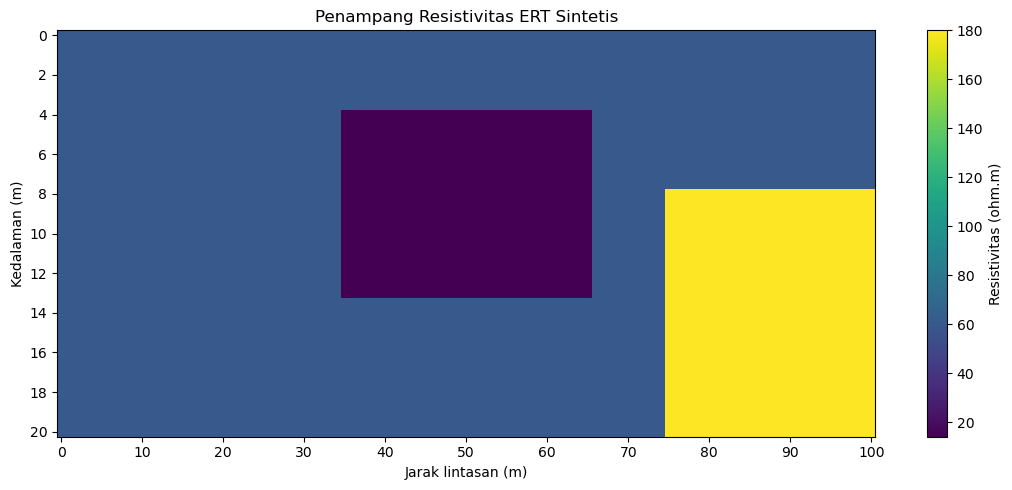

Grafik disimpan sebagai: ert_resistivitas_sintetis.png


In [5]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN MODEL RESISTIVITAS SINTETIS
# ============================================================
x = np.linspace(0, 100, 101)
z = np.linspace(0, 20, 41)
X, Z = np.meshgrid(x, z)

rho = np.full_like(X, 60.0)  # latar belakang (ohm.m)
rho[(X >= 35) & (X <= 65) & (Z >= 4) & (Z <= 13)] = 14.0
rho[(X >= 75) & (Z >= 8)] = 180.0

print("="*55)
print("ERT - MODEL RESISTIVITAS SINTETIS")
print("="*55)
print(f"Resistivitas minimum : {rho.min():.1f} ohm.m")
print(f"Resistivitas maksimum: {rho.max():.1f} ohm.m")
print("Zona rendah          : X 35–65 m, kedalaman 4–13 m")
print("Zona tinggi          : X 75–100 m, kedalaman mulai 8 m")
print("Data merupakan simulasi, bukan data lapangan.")

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.pcolormesh(X, Z, rho, shading="auto", cmap="viridis")
ax.invert_yaxis()
fig.colorbar(im, ax=ax, label="Resistivitas (ohm.m)")
ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Penampang Resistivitas ERT Sintetis")
ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 21, 2))
fig.tight_layout()
filename = "ert_resistivitas_sintetis.png"
fig.savefig(filename, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan sebagai: {filename}")


Zona resistivitas rendah sekitar jarak 35–65 m dan kedalaman 4–13 m dapat berkaitan dengan material lebih konduktif, misalnya lempung atau material jenuh air. Zona resistivitas tinggi di sisi kanan dapat menunjukkan material lebih resistif, kompak, atau relatif kering. Interpretasi litologi tidak dapat dipastikan dari resistivitas saja; perlu dibandingkan dengan kondisi geologi dan data pendukung.

---

### 3. PROMPT INTERPRETASI STRUKTUR BAWAH PERMUKAAN DENGAN METODE MASW

ROLE (R):

Kamu berperan sebagai ahli geofisika yang memahami metode Multichannel Analysis of Surface Waves (MASW), khususnya analisis gelombang permukaan, kurva dispersi, dan profil kecepatan gelombang geser (Vs).

TASK (T):

Gunakan data MASW yang diberikan untuk mengetahui karakteristik bawah permukaan. Analisis hubungan antara frekuensi, kecepatan fase, kurva dispersi, serta profil Vs. Selanjutnya tentukan perubahan kekakuan material terhadap kedalaman dan kemungkinan susunan lapisan bawah permukaan.

CONTEXT (C):

Metode MASW digunakan untuk memperoleh informasi bawah permukaan melalui analisis gelombang permukaan. Data dapat berupa rekaman multichannel, kurva dispersi, maupun hasil inversi berupa profil Vs. Hasil interpretasi digunakan untuk menggambarkan kondisi lapisan dangkal berdasarkan perubahan kecepatan gelombang geser.

INPUT (I):

Masukkan informasi yang tersedia, seperti:
- Data rekaman gelombang permukaan.
- Kurva dispersi.
- Nilai frekuensi dan kecepatan fase.
- Profil kecepatan gelombang geser (Vs).
- Kedalaman setiap lapisan.
- Informasi geologi atau kondisi lapangan jika tersedia.

CONSTRAINTS (K):

Interpretasi harus mengacu pada data MASW yang diberikan. Jangan menentukan litologi secara mutlak hanya berdasarkan nilai Vs. Hubungkan perubahan Vs dengan kemungkinan perubahan kekakuan atau karakter material. Jika terdapat lebih dari satu kemungkinan interpretasi, tampilkan kemungkinan yang paling sesuai dengan data.

OUTPUT (O):

Berikan uraian yang mencakup hasil pembacaan kurva dispersi, perubahan nilai Vs terhadap kedalaman, pembagian lapisan berdasarkan karakter kecepatannya, interpretasi kondisi material bawah permukaan, serta kesimpulan mengenai karakter struktur bawah permukaan.

## Studi Kasus Multichannel Analysis of Surface Waves (MASW)
Simulasi kurva dispersi dan profil kecepatan gelombang geser (Vs). Data dibuat untuk memperlihatkan kecenderungan frekuensi lebih rendah berhubungan dengan kecepatan fase dan kedalaman investigasi yang berbeda, serta perubahan Vs antarlapisan.

MASW - DATA SINTETIS
Rentang frekuensi       : 5.0–40.0 Hz
Rentang kecepatan fase  : 221.2–505.7 m/s
Rentang Vs model        : 160.0–650.0 m/s
Data merupakan simulasi, bukan hasil inversi lapangan.


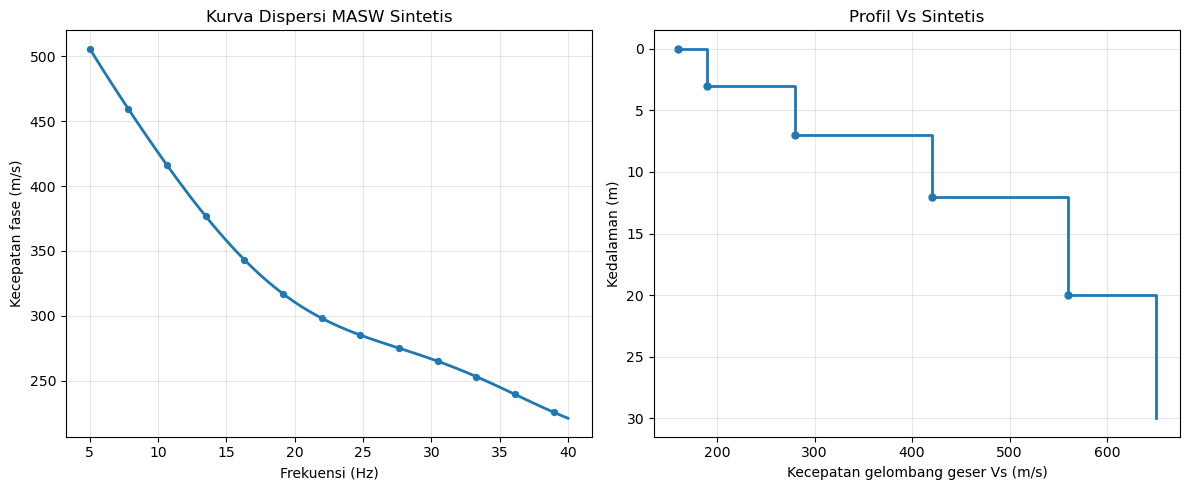

Grafik disimpan sebagai: masw_dispersi_dan_vs.png


In [6]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. KURVA DISPERSI SINTETIS
# ============================================================
freq = np.linspace(5, 40, 100)  # frekuensi (Hz)
phase_velocity = 180 + 420 * np.exp(-freq/18) + 8*np.sin(freq/4)

# Profil Vs sintetis berdasarkan lapisan
depth = np.array([0, 3, 7, 12, 20, 30], dtype=float)
vs = np.array([160, 190, 280, 420, 560, 650], dtype=float)

print("="*55)
print("MASW - DATA SINTETIS")
print("="*55)
print(f"Rentang frekuensi       : {freq.min():.1f}–{freq.max():.1f} Hz")
print(f"Rentang kecepatan fase  : {phase_velocity.min():.1f}–{phase_velocity.max():.1f} m/s")
print(f"Rentang Vs model        : {vs.min():.1f}–{vs.max():.1f} m/s")
print("Data merupakan simulasi, bukan hasil inversi lapangan.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(freq, phase_velocity, linewidth=2)
axes[0].scatter(freq[::8], phase_velocity[::8], s=18)
axes[0].set_xlabel("Frekuensi (Hz)")
axes[0].set_ylabel("Kecepatan fase (m/s)")
axes[0].set_title("Kurva Dispersi MASW Sintetis")
axes[0].grid(True, alpha=0.3)

axes[1].step(vs, depth, where="post", linewidth=2)
axes[1].scatter(vs[:-1], depth[:-1], s=25)
axes[1].invert_yaxis()
axes[1].set_xlabel("Kecepatan gelombang geser Vs (m/s)")
axes[1].set_ylabel("Kedalaman (m)")
axes[1].set_title("Profil Vs Sintetis")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
filename = "masw_dispersi_dan_vs.png"
fig.savefig(filename, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan sebagai: {filename}")



Profil Vs sintetis menunjukkan nilai sekitar 160–280 m/s pada bagian dangkal hingga kedalaman sekitar 7 m, lalu meningkat menjadi sekitar 420–650 m/s pada lapisan yang lebih dalam. Kenaikan Vs dapat menunjukkan material yang semakin kaku atau kompak. Nilai Vs saja tidak cukup untuk menentukan litologi secara pasti. Kurva dispersi yang ditampilkan merupakan ilustrasi dan bukan hasil inversi dari rekaman lapangan.

---

### 4.  PROMPT ANALISIS BAWAH PERMUKAAN MENGGUNAKAN METODE GPR

ROLE (R):

Bertindak sebagai geofisikawan yang menguasai metode Ground Penetrating Radar, pengolahan radargram, analisis refleksi gelombang elektromagnetik, serta identifikasi objek atau struktur dangkal berdasarkan pola reflektor.

TASK (T):

Analisis data GPR yang diberikan untuk memperoleh gambaran kondisi bawah permukaan dangkal. Identifikasi reflektor, perubahan karakter sinyal, pola hiperbola, zona gangguan, maupun indikasi objek bawah permukaan yang dapat dikenali dari radargram.

CONTEXT (C):

Survei GPR dilakukan dengan memanfaatkan gelombang elektromagnetik untuk mendeteksi perubahan sifat material di bawah permukaan. Data dapat berupa radargram hasil pengukuran maupun radargram yang telah melalui proses pengolahan seperti dewow, gain, filtering, background removal, dan koreksi lainnya.

INPUT (I):

Gunakan data atau informasi berikut apabila tersedia:
- Radargram hasil pengukuran.
- Frekuensi antena.
- Jarak lintasan survei.
- Kedalaman atau skala waktu.
- Hasil pengolahan radargram.
- Informasi mengenai target atau kondisi lokasi survei.

CONSTRAINTS (K):

Interpretasi harus berasal dari pola yang terlihat pada radargram. Jangan menyatakan suatu reflektor sebagai objek tertentu apabila tidak terdapat bukti yang cukup. Perhatikan keterbatasan penetrasi GPR akibat kondisi material bawah permukaan. Hindari interpretasi yang tidak berhubungan dengan karakter data.

OUTPUT (O):

Tuliskan hasil analisis secara naratif dengan membahas karakter radargram, reflektor yang dominan, perubahan sinyal terhadap kedalaman atau posisi, kemungkinan struktur maupun objek bawah permukaan, serta kesimpulan mengenai kondisi bawah permukaan yang teridentifikasi menggunakan GPR.

## Studi Kasus Ground Penetrating Radar (GPR)
Radargram sintetis dengan reflektor berlapis dan anomali berbentuk hiperbola. Sumbu vertikal menunjukkan waktu tempuh dua arah.

GPR - RADARGRAM SINTETIS
Panjang lintasan       : 30.0 m
Jendela waktu          : 80.0 ns
Kecepatan asumsi       : 0.10 m/ns
Kedalaman maksimum teori: 4.00 m
Posisi target model    : 14.0 m
Kedalaman target model : 1.2 m
Data merupakan simulasi, bukan data lapangan.


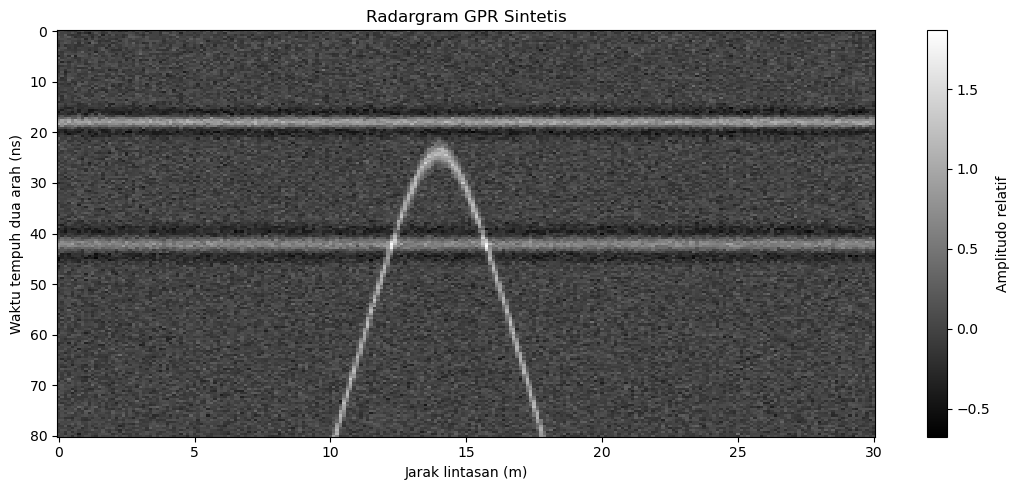

Grafik disimpan sebagai: gpr_radargram_sintetis.png


In [7]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN RADARGRAM GPR SINTETIS
# ============================================================
rng = np.random.default_rng(7)
x = np.linspace(0, 30, 241)
t_ns = np.linspace(0, 80, 201)
X, T = np.meshgrid(x, t_ns)
radar = 0.12 * rng.normal(size=X.shape)

# Reflektor horizontal
radar += 0.9*np.exp(-((T-18)/2.2)**2)*np.cos(2*np.pi*(T-18)/5)
radar += 0.65*np.exp(-((T-42)/3.0)**2)*np.cos(2*np.pi*(T-42)/6)

# Hiperbola target sintetis
v = 0.10  # m/ns
x0, z0 = 14.0, 1.2
t0 = 2*z0/v
hyper_t = np.sqrt(t0**2 + (2*(X-x0)/v)**2)
radar += 1.1*np.exp(-((T-hyper_t)/1.8)**2)

zmax = v*t_ns.max()/2
print("="*55)
print("GPR - RADARGRAM SINTETIS")
print("="*55)
print(f"Panjang lintasan       : {x.max():.1f} m")
print(f"Jendela waktu          : {t_ns.max():.1f} ns")
print(f"Kecepatan asumsi       : {v:.2f} m/ns")
print(f"Kedalaman maksimum teori: {zmax:.2f} m")
print(f"Posisi target model    : {x0:.1f} m")
print(f"Kedalaman target model : {z0:.1f} m")
print("Data merupakan simulasi, bukan data lapangan.")

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.pcolormesh(X, T, radar, shading="auto", cmap="gray")
ax.invert_yaxis()
fig.colorbar(im, ax=ax, label="Amplitudo relatif")
ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("Waktu tempuh dua arah (ns)")
ax.set_title("Radargram GPR Sintetis")
fig.tight_layout()
filename = "gpr_radargram_sintetis.png"
fig.savefig(filename, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan sebagai: {filename}")


Radargram memperlihatkan reflektor horizontal pada beberapa waktu tempuh serta respons hiperbola di sekitar posisi lintasan 14 m. Hiperbola dapat menunjukkan objek lokal atau perubahan sifat material, tetapi bentuk ini tidak cukup untuk memastikan jenis objek. Dengan kecepatan asumsi 0,10 m/ns dan jendela waktu 80 ns, kedalaman maksimum teoritis adalah sekitar 4 m. Kedalaman aktual bergantung pada kecepatan gelombang dan kondisi material.

---

### 5. PROMPT IDENTIFIKASI ZONA ANOMALI BAWAH PERMUKAAN MENGGUNAKAN METODE IP

ROLE (R):

Bertindak sebagai geofisikawan yang berpengalaman dalam metode Induced Polarization (IP), terutama dalam membaca distribusi chargeability dan resistivitas untuk mengenali perubahan sifat material serta kemungkinan zona mineralisasi bawah permukaan.

TASK (T):

Analisis data IP yang tersedia dengan memperhatikan persebaran nilai chargeability dan resistivitas. Identifikasi zona anomali, bandingkan hubungan antara kedua parameter tersebut, kemudian tentukan area yang memiliki indikasi kondisi geologi atau mineralisasi yang berbeda dari lingkungan sekitarnya.

CONTEXT (C):

Metode IP digunakan untuk mengidentifikasi sifat polarisasi material bawah permukaan. Data IP dapat memberikan informasi mengenai chargeability dan resistivitas sehingga keduanya dapat digunakan secara bersamaan dalam interpretasi zona anomali. Analisis dilakukan berdasarkan posisi, kedalaman, intensitas anomali, dan hubungan antara kedua parameter.

INPUT (I):

Masukkan data studi kasus yang tersedia, meliputi:
- Penampang chargeability.
- Penampang resistivitas.
- Nilai atau rentang chargeability.
- Nilai atau rentang resistivitas.
- Posisi dan kedalaman anomali.
- Informasi geologi atau target eksplorasi jika tersedia.

CONSTRAINTS (K):

Interpretasi tidak boleh hanya menggunakan satu parameter apabila data resistivitas dan chargeability tersedia secara bersamaan. Zona dengan nilai tinggi atau rendah harus dibandingkan dengan kondisi sekitarnya. Jangan menyatakan adanya mineralisasi tertentu secara pasti tanpa dukungan data tambahan. Jika ditemukan zona yang hanya bersifat indikatif, gunakan istilah indikasi atau kemungkinan.

OUTPUT (O):

Jelaskan hasil interpretasi dalam bentuk narasi yang mencakup pola distribusi chargeability dan resistivitas, lokasi zona anomali, hubungan kedua parameter, kemungkinan karakter material atau zona mineralisasi, serta kesimpulan mengenai area yang paling menarik berdasarkan hasil survei IP.

## Studi Kasus Induced Polarization (IP)
Model IP sintetis memperlihatkan dua parameter, yaitu resistivitas dan chargeability, agar hubungan keduanya dapat dianalisis secara bersamaan.

INDUCED POLARIZATION (IP) - DATA SINTETIS
Rentang resistivitas : 28.0–80.0 ohm.m
Rentang chargeability: 8.0–32.0 mV/V
Zona anomali         : X = 40–65 m
Kedalaman anomali    : 6–18 m
Data merupakan simulasi, bukan data lapangan.


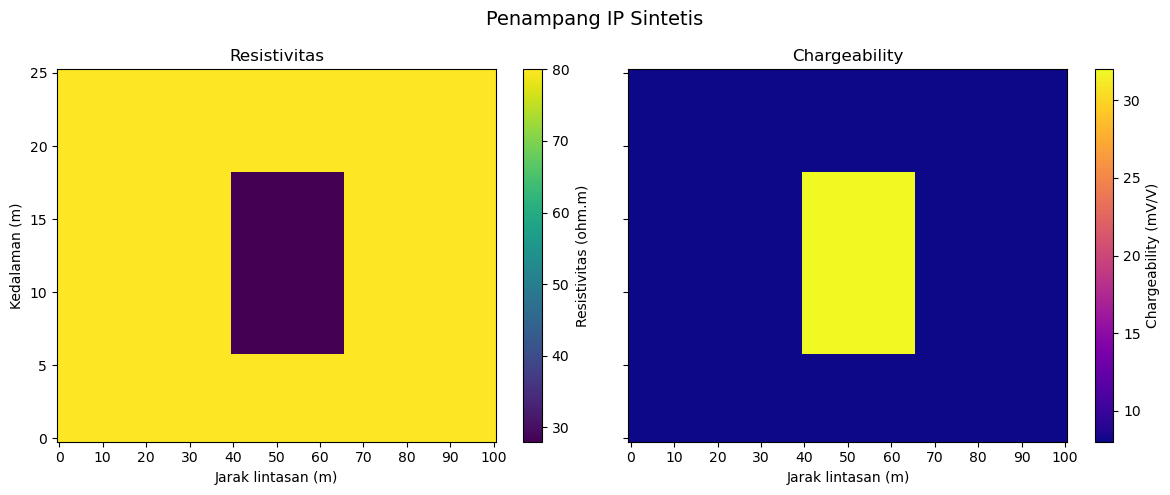

Grafik disimpan sebagai: ip_resistivitas_chargeability.png


In [8]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMBUATAN MODEL IP SINTETIS
# ============================================================
x = np.linspace(0, 100, 101)
z = np.linspace(0, 25, 51)
X, Z = np.meshgrid(x, z)

rho = np.full_like(X, 80.0)  # ohm.m
chargeability = np.full_like(X, 8.0)  # mV/V

target = (X >= 40) & (X <= 65) & (Z >= 6) & (Z <= 18)
rho[target] = 28.0
chargeability[target] = 32.0

print("="*58)
print("INDUCED POLARIZATION (IP) - DATA SINTETIS")
print("="*58)
print(f"Rentang resistivitas : {rho.min():.1f}–{rho.max():.1f} ohm.m")
print(f"Rentang chargeability: {chargeability.min():.1f}–{chargeability.max():.1f} mV/V")
print("Zona anomali         : X = 40–65 m")
print("Kedalaman anomali    : 6–18 m")
print("Data merupakan simulasi, bukan data lapangan.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
im1 = axes[0].pcolormesh(X, Z, rho, shading="auto", cmap="viridis")
axes[0].set_title("Resistivitas")
axes[0].set_xlabel("Jarak lintasan (m)")
axes[0].set_ylabel("Kedalaman (m)")
fig.colorbar(im1, ax=axes[0], label="Resistivitas (ohm.m)")

im2 = axes[1].pcolormesh(X, Z, chargeability, shading="auto", cmap="plasma")
axes[1].set_title("Chargeability")
axes[1].set_xlabel("Jarak lintasan (m)")
fig.colorbar(im2, ax=axes[1], label="Chargeability (mV/V)")

for ax in axes:
    ax.invert_yaxis()
    ax.set_xticks(np.arange(0, 101, 10))
    ax.set_yticks(np.arange(0, 26, 5))

fig.suptitle("Penampang IP Sintetis", fontsize=14)
fig.tight_layout()
filename = "ip_resistivitas_chargeability.png"
fig.savefig(filename, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan sebagai: {filename}")


Zona pada jarak 40–65 m dan kedalaman 6–18 m memiliki resistivitas lebih rendah (28 ohm.m) serta chargeability lebih tinggi (32 mV/V) daripada latar belakang. Kombinasi tersebut menunjukkan respons listrik yang berbeda dan dapat menjadi zona yang perlu ditinjau lebih lanjut. Hal ini belum membuktikan mineralisasi tertentu karena material lempungan dan faktor geologi lain juga dapat memengaruhi respons IP. Data geologi, geokimia, atau pengeboran diperlukan untuk konfirmasi.

---